In [9]:
import numpy as np
from qiskit import QuantumCircuit

def prepare_signal(signal):
    signal = np.asarray(signal, dtype=complex)

    n = int(np.log2(len(signal)))

    if len(signal) != 2**n:
        raise ValueError("Signal length must be a power of two.")

    norm = np.linalg.norm(signal)

    if norm == 0:
        raise ValueError("Signal cannot be zero.")

    amplitudes = signal / norm

    qc = QuantumCircuit(n)
    qc.initialize(amplitudes, range(n))

    return qc

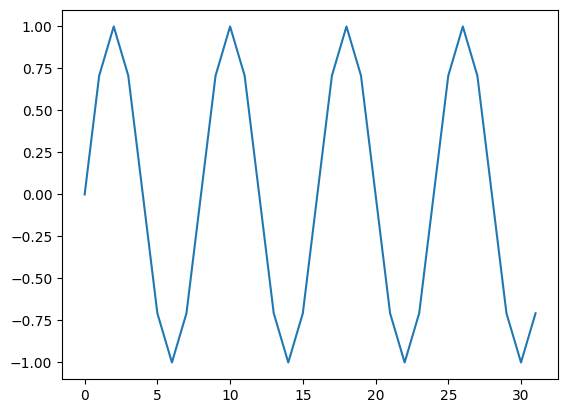

In [27]:
import matplotlib.pyplot as plt


N = 2**5
k = 4

omega = 2 * np.pi * k / N

periodic_signal = np.sin([i * omega for i in range(N)])

plt.plot(periodic_signal)

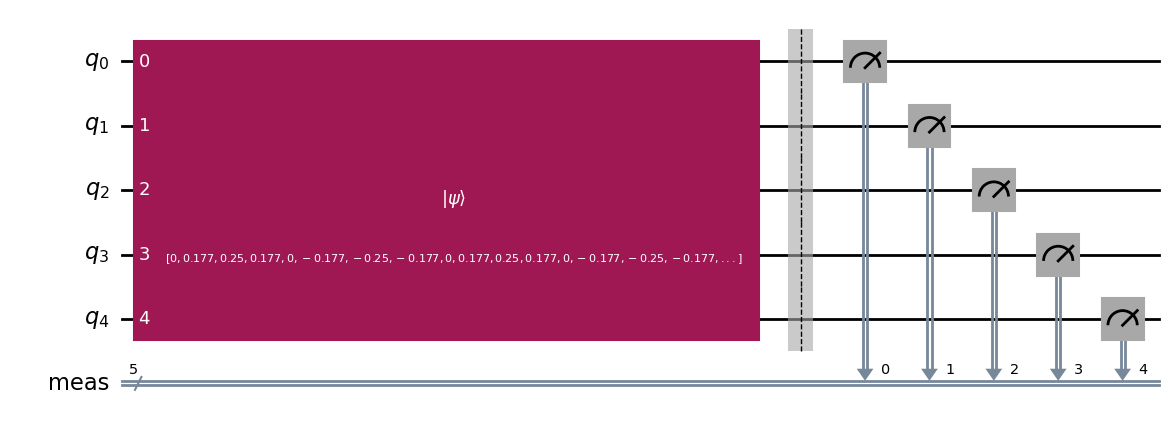

In [28]:
qc = prepare_signal(periodic_signal)
qc.measure_all()
qc.draw('mpl')


$$
\sum_j \sin^2(2\pi kj/N)=\frac{N}{2}
$$

00001 1 0.03036
00010 2 0.06221
00011 3 0.03128
00101 5 0.03185
00110 6 0.06212
00111 7 0.03174
01001 9 0.03043
01010 10 0.06339
01011 11 0.03042
01101 13 0.03059
01110 14 0.06284
01111 15 0.03134
10001 17 0.03167
10010 18 0.06168
10011 19 0.03087
10101 21 0.03171
10110 22 0.06208
10111 23 0.03094
11001 25 0.03184
11010 26 0.06266
11011 27 0.03182
11101 29 0.03075
11110 30 0.06291
11111 31 0.0325


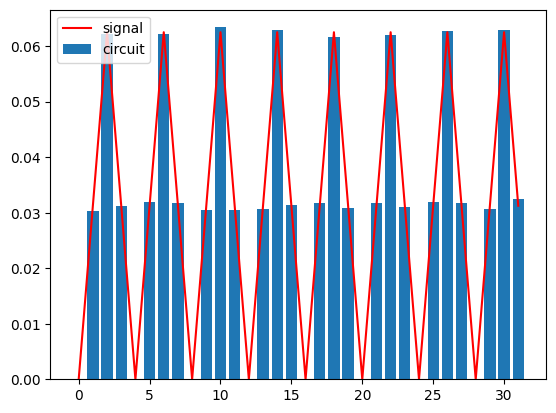

In [63]:
from qiskit.primitives import StatevectorSampler


sampler = StatevectorSampler()
result = sampler.run([qc], shots=100000).result()
counts = result[0].data.meas.get_counts()

counts_ordered = dict(sorted(counts.items(), key=lambda item: int(item[0], 2)))

values = np.zeros(2**qc.num_qubits)
for k, v in counts_ordered.items():
    bit_num = int(k, 2)
    print(k, bit_num, v/100000)
    values[bit_num] = v/100000

import matplotlib.pyplot as plt

plt.bar(range(2**qc.num_qubits), values, label='circuit')
plt.plot(range(2**qc.num_qubits), periodic_signal**2/N*2, color='red', label='signal')
plt.legend()


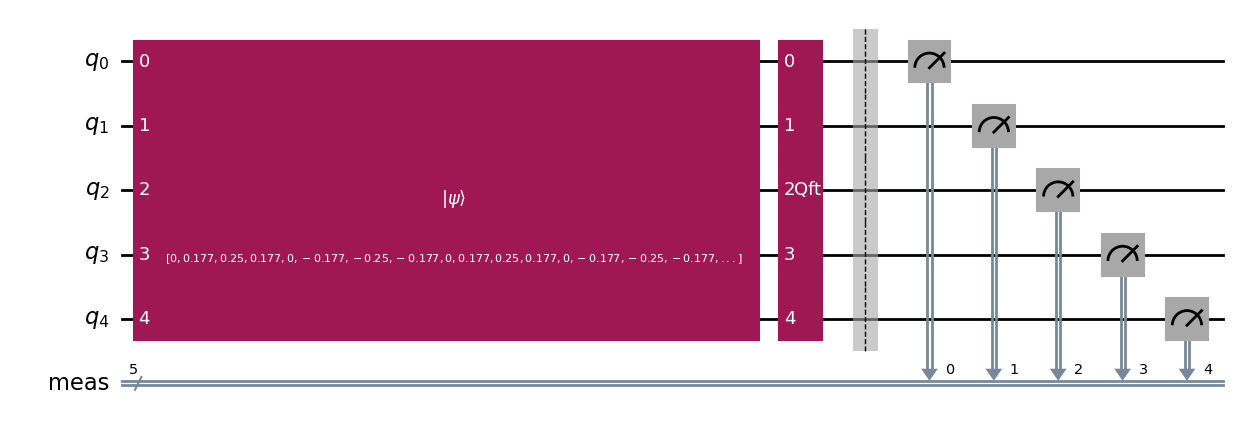

In [46]:
from qiskit.circuit.library import QFTGate


# Prepare the periodic state
qc_ft = prepare_signal(periodic_signal)

# Apply QFT
qc_ft.append(QFTGate(qc.num_qubits), range(qc.num_qubits))
qc_ft.measure_all()
qc_ft.draw('mpl')

00100 4 0.05007
11100 28 0.04993


<BarContainer object of 32 artists>

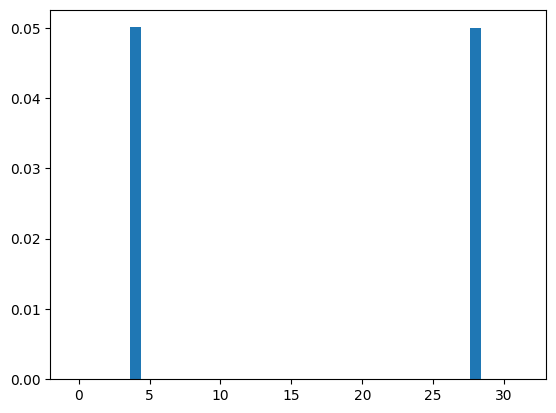

In [47]:
from qiskit.primitives import StatevectorSampler

sampler = StatevectorSampler()
result = sampler.run([qc_ft], shots=100000).result()
counts = result[0].data.meas.get_counts()
#print(counts)
counts_ordered = dict(sorted(counts.items(), key=lambda item: int(item[0], 2)))

n_states = 2**qc.num_qubits
values = np.zeros(n_states)

for k, v in counts_ordered.items():
    bit_num = int(k, 2)
    print(k, bit_num, v/1000000)
    values[bit_num] = v/1000000

import matplotlib.pyplot as plt

plt.bar(range(n_states), values)